# 01 — Exploration : un bureau, ses cycles et sa relation à la température

**Données** : Building Data Genome Project 2 (BDG2), compteurs électriques horaires 2016–2017.
**Bâtiment** : `Fox_office_Brandy` — bureau universitaire, 3 922 m², Tempe (Arizona), construit en 1985.

Questions :
1. Quelle est la qualité des données (trous, zéros, valeurs aberrantes) ?
2. Quels cycles voit-on (jour/nuit, semaine/week-end, saisons) ?
3. Comment la consommation dépend-elle de la température extérieure (signature énergétique) ?

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load_building, load_metadata

FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
BUILDING = "Fox_office_Brandy"

## 1. Métadonnées et chargement

In [2]:
meta = load_metadata()
meta.loc[BUILDING].dropna()

site_id                                 Fox
building_id_kaggle                    274.0
site_id_kaggle                          2.0
primaryspaceusage                    Office
sub_primaryspaceusage                Office
sqm                                  3921.8
sqft                                42214.0
lat                               33.424425
lng                              -111.92814
timezone                        US/Mountain
electricity                             Yes
industry                          Education
subindustry              College/University
yearbuilt                            1985.0
Name: Fox_office_Brandy, dtype: object

In [3]:
df = load_building(BUILDING)
df[["kwh", "airTemperature", "dewTemperature", "windSpeed"]].describe().round(1)

,kwh,airTemperature,dewTemperature,windSpeed
count,17534.0,17542.0,17542.0,17531.0
mean,32.2,25.1,4.0,2.9
std,21.9,9.1,7.6,1.9
min,1.7,2.2,-19.4,0.0
25%,15.6,17.8,-1.7,1.5
50%,22.9,25.6,3.3,2.6
75%,42.4,32.2,8.9,4.1
max,115.6,48.3,24.4,15.4


## 2. Qualité des données

Avant toute modélisation : combien d'heures manquantes, de zéros, et y a-t-il des plateaux suspects (compteur figé) ?

In [4]:
s = df["kwh"]
print(f"Période        : {s.index.min():%Y-%m-%d} → {s.index.max():%Y-%m-%d} ({len(s):,} heures)")
print(f"Manquants      : {s.isna().sum()} h ({s.isna().mean():.2%})")
print(f"Zéros          : {(s == 0).sum()} h")
print(f"Météo manquante: {df['airTemperature'].isna().sum()} h")

# Plateaux : même valeur répétée ≥ 6 h d'affilée (compteur figé ?)
runs = (s != s.shift()).cumsum()
run_len = s.groupby(runs).transform("size")
print(f"Heures dans un plateau ≥ 6 h : {(run_len >= 6).sum()}")

Période        : 2016-01-01 → 2017-12-31 (17,544 heures)
Manquants      : 10 h (0.06%)
Zéros          : 0 h
Météo manquante: 2 h
Heures dans un plateau ≥ 6 h : 0


## 3. Une semaine type

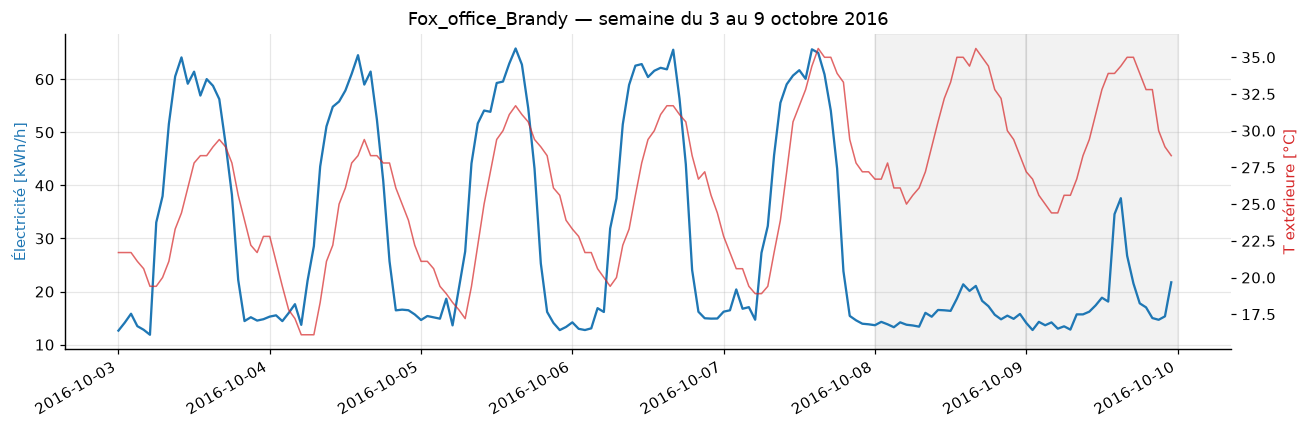

In [5]:
week = df.loc["2016-10-03":"2016-10-09"]   # lundi → dimanche, hors vacances universitaires

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(week.index, week["kwh"], color="tab:blue", lw=1.5, label="Électricité")
ax1.set_ylabel("Électricité [kWh/h]", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(week.index, week["airTemperature"], color="tab:red", lw=1, alpha=0.7, label="T ext")
ax2.set_ylabel("T extérieure [°C]", color="tab:red")
ax2.grid(False)
for d in pd.date_range("2016-10-08", periods=2):   # week-end grisé
    ax1.axvspan(d, d + pd.Timedelta(days=1), color="grey", alpha=0.1)
ax1.set_title(f"{BUILDING} — semaine du 3 au 9 octobre 2016")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG / "01_semaine.png")

**Lecture** : talon nocturne bas, montée le matin à l'arrivée des occupants, plateau en journée, et week-end proche du talon.
Le pic de journée suit aussi la température : en Arizona, la climatisation est électrique.

## 4. Une année complète

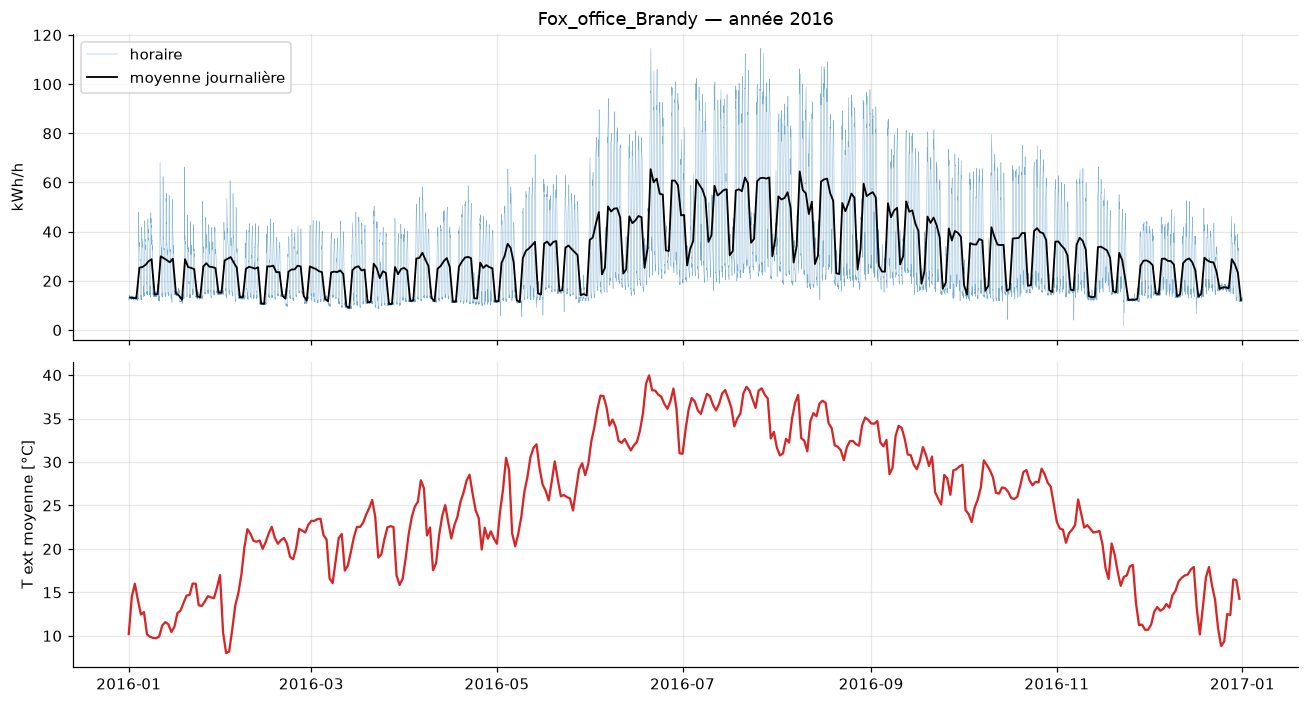

In [6]:
year = df.loc["2016"]
daily = year["kwh"].resample("D").sum()

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].plot(year.index, year["kwh"], lw=0.3, color="tab:blue", alpha=0.6, label="horaire")
axes[0].plot(daily.index + pd.Timedelta(hours=12), daily / 24, color="k", lw=1.2, label="moyenne journalière")
axes[0].set_ylabel("kWh/h")
axes[0].legend(loc="upper left")
axes[0].set_title(f"{BUILDING} — année 2016")
axes[1].plot(year["airTemperature"].resample("D").mean(), color="tab:red")
axes[1].set_ylabel("T ext moyenne [°C]")
fig.tight_layout()
fig.savefig(FIG / "01_annee.png")

## 5. Carte de chaleur heure × jour

Toute l'année d'un coup d'œil : chaque colonne est un jour, chaque ligne une heure.
On y repère les horaires d'occupation, les week-ends, les vacances et l'effet saisonnier.

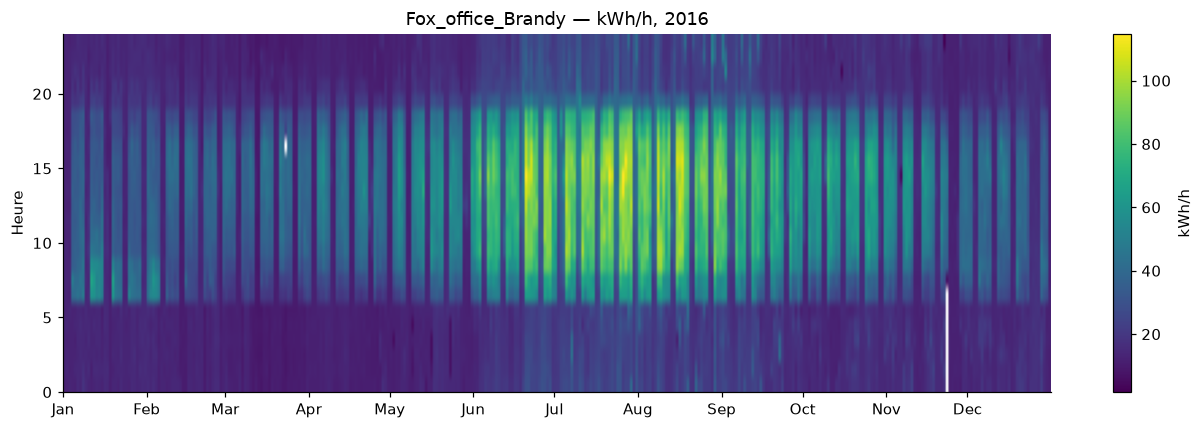

In [7]:
pivot = year.assign(date=year.index.date, hour=year.index.hour).pivot_table(
    index="hour", columns="date", values="kwh")

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(pivot, aspect="auto", cmap="viridis", origin="lower",
               extent=[0, pivot.shape[1], 0, 24])
months = pd.date_range("2016-01-01", "2016-12-01", freq="MS")
ax.set_xticks([(m - pd.Timestamp("2016-01-01")).days for m in months], [m.strftime("%b") for m in months])
ax.set_ylabel("Heure")
ax.grid(False)
ax.set_title(f"{BUILDING} — kWh/h, 2016")
fig.colorbar(im, ax=ax, label="kWh/h")
fig.tight_layout()
fig.savefig(FIG / "01_heatmap.png")

## 6. Profils moyens par heure : semaine vs week-end, été vs hiver

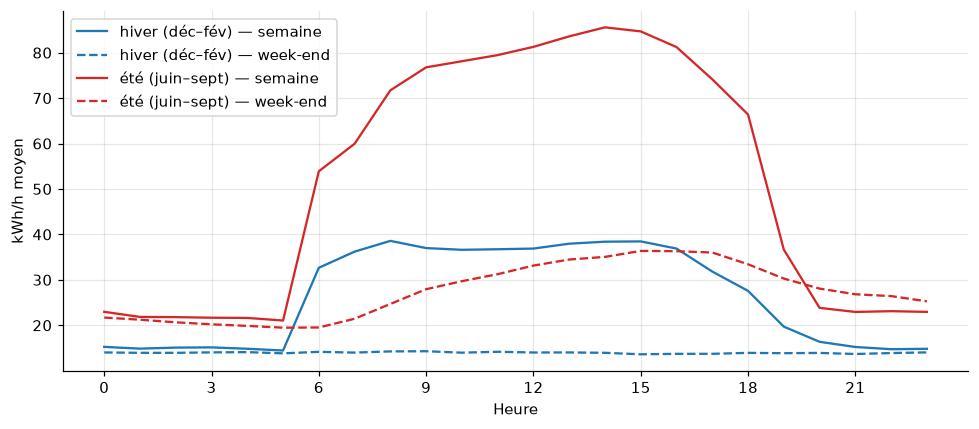

In [8]:
d = df.assign(hour=df.index.hour,
              weekend=df.index.day_of_week >= 5,
              saison=np.where(df.index.month.isin([6, 7, 8, 9]), "été (juin–sept)",
                     np.where(df.index.month.isin([12, 1, 2]), "hiver (déc–fév)", None)))
prof = d.dropna(subset=["saison"]).groupby(["saison", "weekend", "hour"])["kwh"].mean()

fig, ax = plt.subplots(figsize=(9, 4))
for (saison, we), g in prof.groupby(level=[0, 1]):
    ax.plot(g.index.get_level_values("hour"), g.values,
            ls="--" if we else "-", color="tab:red" if "été" in saison else "tab:blue",
            label=f"{saison} — {'week-end' if we else 'semaine'}")
ax.set_xlabel("Heure")
ax.set_ylabel("kWh/h moyen")
ax.set_xticks(range(0, 24, 3))
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "01_profils.png")

## 7. Signature énergétique : consommation vs température

En thermique du bâtiment, on trace la consommation journalière contre la température moyenne journalière.
Avec une clim électrique, on attend un **modèle à point d'inflexion (change-point)** :
- en dessous d'une température d'équilibre, consommation ≈ constante (talon : éclairage, bureautique, ventilation) ;
- au-dessus, la consommation croît ~linéairement avec T (charge de refroidissement ∝ UA·(T_ext − T_int) + apports).

On sépare jours ouvrés et week-ends, sinon l'occupation brouille la relation.

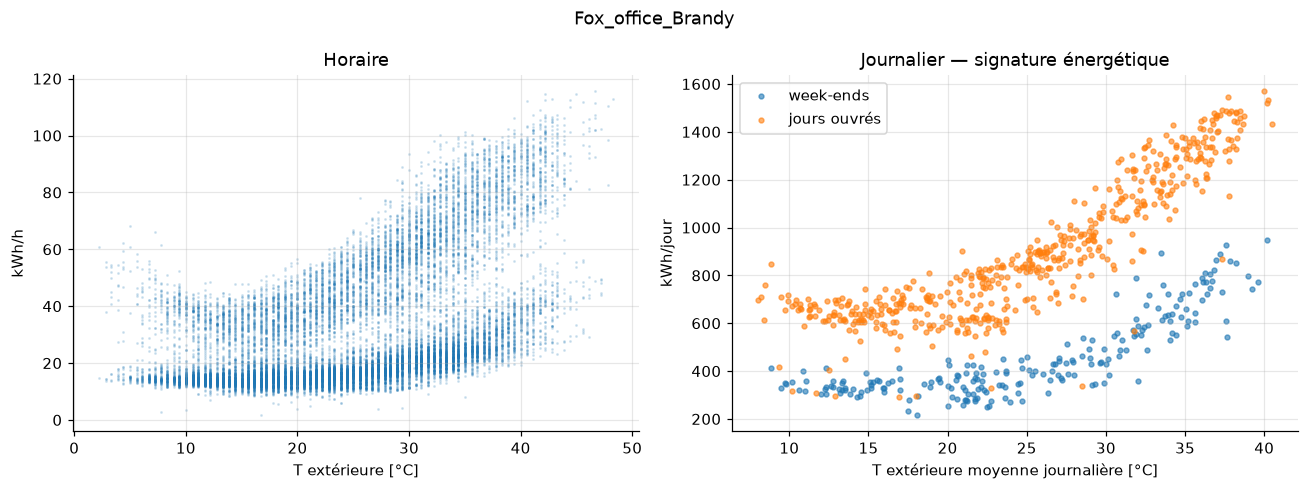

In [9]:
day = df.resample("D").agg({"kwh": "sum", "airTemperature": "mean"}).dropna()
day["ouvré"] = day.index.day_of_week < 5

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) nuage horaire
axes[0].scatter(df["airTemperature"], df["kwh"], s=1, alpha=0.15, color="tab:blue")
axes[0].set_xlabel("T extérieure [°C]")
axes[0].set_ylabel("kWh/h")
axes[0].set_title("Horaire")

# (b) signature journalière
for ouvre, g in day.groupby("ouvré"):
    axes[1].scatter(g["airTemperature"], g["kwh"], s=10, alpha=0.6,
                    label="jours ouvrés" if ouvre else "week-ends")
axes[1].set_xlabel("T extérieure moyenne journalière [°C]")
axes[1].set_ylabel("kWh/jour")
axes[1].set_title("Journalier — signature énergétique")
axes[1].legend()
fig.suptitle(BUILDING)
fig.tight_layout()
fig.savefig(FIG / "01_signature.png")

### Premier modèle physique : change-point à 3 paramètres (3P cooling)

$E = \beta_0 + \beta_1 \cdot \max(0,\ T - T_b)$ — on cherche $T_b$ par balayage et moindres carrés.
C'est la forme standard ASHRAE Guideline 14, qu'on réutilisera en semaine 5 (M&V).

Jours ouvrés : T_b = 21.8 °C | talon = 645 kWh/j | pente = 47.2 kWh/j/K | R² = 0.87


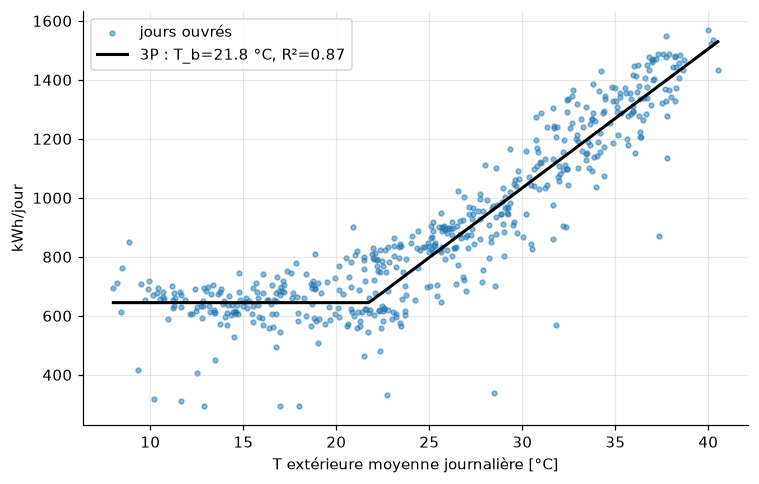

In [10]:
def fit_3p_cooling(T, E, grid=np.arange(5, 35, 0.25)):
    best = None
    for tb in grid:
        X = np.column_stack([np.ones_like(T), np.maximum(0, T - tb)])
        beta, res, *_ = np.linalg.lstsq(X, E, rcond=None)
        sse = ((E - X @ beta) ** 2).sum()
        if best is None or sse < best[0]:
            best = (sse, tb, beta)
    sse, tb, beta = best
    r2 = 1 - sse / ((E - E.mean()) ** 2).sum()
    return tb, beta, r2

wd = day[day["ouvré"]]
tb, (b0, b1), r2 = fit_3p_cooling(wd["airTemperature"].values, wd["kwh"].values)
print(f"Jours ouvrés : T_b = {tb:.1f} °C | talon = {b0:.0f} kWh/j | pente = {b1:.1f} kWh/j/K | R² = {r2:.2f}")

Tg = np.linspace(day["airTemperature"].min(), day["airTemperature"].max(), 200)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(wd["airTemperature"], wd["kwh"], s=10, alpha=0.5, label="jours ouvrés")
ax.plot(Tg, b0 + b1 * np.maximum(0, Tg - tb), color="k", lw=2, label=f"3P : T_b={tb:.1f} °C, R²={r2:.2f}")
ax.set_xlabel("T extérieure moyenne journalière [°C]")
ax.set_ylabel("kWh/jour")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "01_changepoint.png")

## 8. À retenir pour la suite

- Données très propres pour ce bâtiment (< 0,1 % de trous) → interpolation courte suffisante.
- Deux moteurs principaux : **occupation** (heure × jour de semaine, vacances) et **température** (clim).
- Le nuage horaire est très dispersé car il mélange occupé/inoccupé → un modèle doit croiser heure, jour et météo :
  c'est exactement ce que feront les baselines (semaine 2) puis LightGBM (semaine 3).
- La dispersion résiduelle autour du change-point (jours fériés, vacances universitaires, dérives) est la matière première de la détection d'anomalies (semaine 4).